# 🚗 เทรนโมเดล DeepLabV3+ (ResNet50 + SSL) ด้วยชุดข้อมูลถนนไทยล้วน (`thai_road_lane`)

สมุดงานนี้ออกแบบสำหรับ **เทรนถนนไทยล้วน (Scratch - ไม่ใช้ CULane)**:
- **Architecture:** `DeepLabV3Plus`
- **Encoder (Backbone):** `resnet50`
- **Encoder Weights:** `ssl` (โหลดเฉพาะ weights เริ่มต้นของ backbone จาก SSL MoCo v2, ส่วน Decoder เริ่มจากสุ่ม)
- **Weights จาก CULane:** **ไม่ใช้ (INIT_WEIGHTS = None)** เพื่อทดสอบประสิทธิภาพการเทรนบนถนนไทยอย่างเดียว
- **ชุดข้อมูล:** `thai_road_lane` (Train 749 ภาพ, Val 97 ภาพ, Test 191 ภาพ)
- **Hyperparameters:** `EPOCHS = 30`, `BATCH_SIZE = 16`, `LR = 1e-4` (ใช้ 1e-4 สำหรับเทรนใหม่)
- **เมตริกประเมินผล:** IoU, Precision, Recall, F1-Score (Normal, Curve, Night, ALL)

In [2]:
# ตรวจสอบการติดตั้งแพ็กเกจที่จำเป็น
!pip install -q opencv-python matplotlib numpy segmentation-models-pytorch tqdm pandas

In [3]:
import os
import sys
import csv
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

# ตรวจสอบอุปกรณ์ประมวลผล
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️  ใช้อุปกรณ์: {device}")
if device.type == "cuda":
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM ทั้งหมด: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

🖥️  ใช้อุปกรณ์: cuda
   GPU: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition MIG 1g.24gb
   VRAM ทั้งหมด: 25.37 GB


## 📐 ฟังก์ชันคำนวณเมตริก (IoU, Precision, Recall, F1-score)
*ไม่มีเมตริกมุมความชัน (Slope Error) ตามข้อกำหนดของโปรเจกต์*

In [4]:
def calculate_iou(pred_mask, true_mask, threshold=0.5):
    """คำนวณ IoU ระหว่าง Prediction กับ Ground Truth"""
    pred_bin = (pred_mask > threshold).bool()
    true_bin = (true_mask > 0.5).bool()
    intersection = (pred_bin & true_bin).sum().float()
    union = (pred_bin | true_bin).sum().float()
    if union == 0:
        return 1.0 if intersection == 0 else 0.0
    return (intersection / union).item()


def calculate_precision_recall_f1(pred_mask, true_mask, threshold=0.5):
    """คำนวณ Precision, Recall และ F1-score ระดับพิกเซล"""
    pred_bin = (pred_mask > threshold).bool()
    true_bin = (true_mask > 0.5).bool()
    tp = (pred_bin & true_bin).sum().float()
    fp = (pred_bin & ~true_bin).sum().float()
    fn = (~pred_bin & true_bin).sum().float()

    precision = (tp / (tp + fp)).item() if (tp + fp) > 0 else 0.0
    recall = (tp / (tp + fn)).item() if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    return precision, recall, f1

## 📉 Loss Functions (BCE Loss + Dice Loss)

In [5]:
class DiceLoss(nn.Module):
    """Dice Loss สำหรับ Binary Segmentation"""
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, inputs, targets):
        inputs = torch.sigmoid(inputs.float()).view(-1)
        targets = targets.float().view(-1)
        intersection = (inputs * targets).sum()
        dice = (2.0 * intersection + self.smooth) / (inputs.sum() + targets.sum() + self.smooth)
        return 1.0 - dice


bce_criterion = nn.BCEWithLogitsLoss()
dice_criterion = DiceLoss()

## 📂 Dataset Class สำหรับโหลดภาพถนนไทย (`thai_road_lane`)

In [6]:
IMG_SIZE = (448, 800)  # (H, W) ตรงตามโครงสร้างโมเดล


class ThaiLaneDataset(Dataset):
    """โหลดภาพถนนไทยตาม CSV split (train, val, test)"""
    def __init__(self, csv_file, img_dir, mask_dir, augment=False):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.augment = augment
        self.df = pd.read_csv(csv_file)
        self.samples = self.df["filename"].tolist()
        self.categories = self.df["category"].tolist() if "category" in self.df.columns else ["normal"] * len(self.samples)

        # สถิติค่าสี ImageNet / SSL MoCo v2
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1, 1, 3)
        self.std  = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1, 1, 3)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        fname = self.samples[idx]
        img_p = os.path.join(self.img_dir, fname)
        mask_name = os.path.splitext(fname)[0] + ".png"
        mask_p = os.path.join(self.mask_dir, mask_name)

        # โหลดภาพ BGR -> RGB
        img = cv2.imread(img_p)
        if img is None:
            raise FileNotFoundError(f"ไม่พบภาพ: {img_p}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if img.shape[:2] != IMG_SIZE:
            img = cv2.resize(img, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_LINEAR)

        # โหลด mask
        mask = cv2.imread(mask_p, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise FileNotFoundError(f"ไม่พบ mask: {mask_p}")
        if mask.shape[:2] != IMG_SIZE:
            mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)

        # Data Augmentation เฉพาะ train
        if self.augment:
            if np.random.rand() > 0.5:
                img = np.fliplr(img).copy()
                mask = np.fliplr(mask).copy()
            if np.random.rand() > 0.5:
                factor = np.random.uniform(0.7, 1.3)
                img = np.clip(img * factor, 0, 255).astype(np.uint8)

        # Normalize [0, 1] และแปลงเป็น Tensor
        img_norm = (img.astype(np.float32) / 255.0 - self.mean) / self.std
        img_tensor = torch.from_numpy(img_norm.transpose(2, 0, 1)).float()
        mask_tensor = torch.from_numpy((mask > 127).astype(np.float32)).unsqueeze(0)

        return img_tensor, mask_tensor

## 📊 ฟังก์ชันวาดกราฟประวัติการเทรน (4 ช่องมาตรฐาน)

In [7]:
def save_training_plot(history_train_loss, history_val_loss,
                       history_train_iou, history_val_iou,
                       history_train_recall, history_val_recall,
                       history_train_f1, history_val_f1,
                       graph_path):
    """วาดกราฟ 4 ช่องตามมาตรฐานของโปรเจกต์"""
    plt.figure(figsize=(14, 10))

    # 1. Loss
    plt.subplot(2, 2, 1)
    plt.plot(history_train_loss, label="Loss", color="red")
    plt.plot(history_val_loss, label="Val Loss", color="orange")
    plt.title("Loss History", fontsize=12, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(loc="upper right")

    # 2. Accuracy (IoU)
    plt.subplot(2, 2, 2)
    plt.plot(history_train_iou, label="Accuracy (IoU)", color="green")
    plt.plot(history_val_iou, label="Val Accuracy (IoU)", color="blue")
    plt.title("Accuracy (IoU) History", fontsize=12, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend(loc="upper left")

    # 3. Recall
    plt.subplot(2, 2, 3)
    plt.plot(history_train_recall, label="Recall", color="purple")
    plt.plot(history_val_recall, label="Val Recall", color="magenta")
    plt.title("Recall History", fontsize=12, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Recall")
    plt.legend(loc="upper left")

    # 4. F1-score
    plt.subplot(2, 2, 4)
    plt.plot(history_train_f1, label="F1-score", color="teal")
    plt.plot(history_val_f1, label="Val F1-score", color="navy")
    plt.title("F1-score History", fontsize=12, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("F1")
    plt.legend(loc="upper left")

    plt.tight_layout()
    os.makedirs(os.path.dirname(graph_path), exist_ok=True)
    plt.savefig(graph_path, dpi=110)
    plt.close()
    print(f"📈 บันทึกกราฟไว้ที่: {graph_path}")

## 🔧 CONFIG — ตั้งค่าเทรนถนนไทยล้วน (Scratch - ไม่ใช้ CULane)

In [8]:
# ==================== แก้ตรงนี้อย่างเดียว ====================
ARCH            = "DeepLabV3Plus"
ENCODER_NAME    = "resnet50"
ENCODER_WEIGHTS = "ssl"            # โหลดเฉพาะ feature weights ของ backbone ResNet50
INIT_WEIGHTS    = None             # None = ไม่โหลด weights CULane (เทรนไทยล้วนตั้งแต่ศูนย์)

# ปรับ path อัตโนมัติ (รองรับรันทั้งจาก root หรือจากโฟลเดอร์ notebooks/)
ROOT_DIR        = ".." if os.path.exists("../thai_road_lane") else "."
DATASET_ROOT    = os.path.join(ROOT_DIR, "thai_road_lane")

EPOCHS          = 30
BATCH_SIZE      = 16
LEARNING_RATE   = 1e-4             # 1e-4 สำหรับเทรนใหม่ตั้งแต่ศูนย์ (ไม่ต้องใช้ 1e-5 ของ fine-tune)
NUM_WORKERS     = 4
USE_AMP         = True             # Mixed precision
TAG             = "thai_scratch_dlv3p_r50_ssl"
# ================================================================

print(f"🚀 โมเดล: {ARCH} + {ENCODER_NAME} (encoder_weights='{ENCODER_WEIGHTS}')")
print(f"   โหมด: เทรนถนนไทยล้วน (Scratch - ไม่ใช้ CULane weights)")
print(f"   ชุดข้อมูล: {DATASET_ROOT} (พบโฟลเดอร์: {os.path.exists(DATASET_ROOT)})")
print(f"   Epochs: {EPOCHS} | Batch Size: {BATCH_SIZE} | LR: {LEARNING_RATE}")

🚀 โมเดล: DeepLabV3Plus + resnet50 (encoder_weights='ssl')
   โหมด: เทรนถนนไทยล้วน (Scratch - ไม่ใช้ CULane weights)
   ชุดข้อมูล: ../thai_road_lane (พบโฟลเดอร์: True)
   Epochs: 30 | Batch Size: 16 | LR: 0.0001


## 🏗️ สร้างโมเดล DeepLabV3+ (เริ่มจาก Encoder SSL, Decoder สุ่มใหม่)

In [9]:
def build_model(init_path=None):
    if init_path and os.path.exists(init_path):
        model = getattr(smp, ARCH)(
            encoder_name=ENCODER_NAME,
            encoder_weights=None,
            in_channels=3,
            classes=1
        )
        state = torch.load(init_path, map_location="cpu", weights_only=False)
        if isinstance(state, dict) and "model_state_dict" in state:
            state = state["model_state_dict"]
        model.load_state_dict(state)
        print(f"✅ โหลด Weights ตั้งต้นสำเร็จ: {os.path.basename(init_path)}")
    else:
        # เทรนไทยล้วนจากศูนย์ (ใช้ weights ของ encoder เท่านั้น ส่วนหัว decoder สุ่มใหม่)
        model = getattr(smp, ARCH)(
            encoder_name=ENCODER_NAME,
            encoder_weights=ENCODER_WEIGHTS,
            in_channels=3,
            classes=1
        )
        print(f"🆕 สร้างโมเดลเทรนไทยล้วน (Scratch): {ARCH} + {ENCODER_NAME} (encoder_weights='{ENCODER_WEIGHTS}')")
    return model.to(device)

model = build_model(INIT_WEIGHTS)

🆕 สร้างโมเดลเทรนไทยล้วน (Scratch): DeepLabV3Plus + resnet50 (encoder_weights='ssl')


## 🏃‍♂️ รันการเทรนบนชุดข้อมูลถนนไทย (30 Epochs)

In [10]:
# เตรียม DataLoaders
train_ds = ThaiLaneDataset(f"{DATASET_ROOT}/train_list.csv", f"{DATASET_ROOT}/images", f"{DATASET_ROOT}/masks", augment=True)
val_ds   = ThaiLaneDataset(f"{DATASET_ROOT}/val_list.csv", f"{DATASET_ROOT}/images", f"{DATASET_ROOT}/masks", augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"📊 ขนาดข้อมูล: Train {len(train_ds)} ภาพ | Val {len(val_ds)} ภาพ")

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)
scaler    = torch.amp.GradScaler("cuda", enabled=USE_AMP)

best_f1 = 0.0
best_epoch = 0
best_model_path  = os.path.join(ROOT_DIR, "models", f"{TAG}_best_f1.pth")
final_model_path = os.path.join(ROOT_DIR, "models", f"{TAG}_final.pth")
resume_ckpt_path = os.path.join(ROOT_DIR, "models", f"{TAG}_resume.pth")
csv_history_path = os.path.join(ROOT_DIR, "results", "thai", f"history_{TAG}.csv")
graph_path       = os.path.join(ROOT_DIR, "results", "thai", f"training_history_{TAG}.png")

history_train_loss, history_val_loss = [], []
history_train_iou,  history_val_iou  = [], []
history_train_rec,  history_val_rec  = [], []
history_train_f1,   history_val_f1   = [], []

start_epoch = 1

# ระบบ Auto-Resume: ตรวจหา Checkpoint เดิมก่อนเริ่มเทรน
if os.path.exists(resume_ckpt_path):
    print(f"🔄 ตรวจพบ Resume Checkpoint: {resume_ckpt_path}")
    ckpt = torch.load(resume_ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    if "scaler_state_dict" in ckpt:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    best_f1 = ckpt.get("best_f1", 0.0)
    best_epoch = ckpt.get("best_epoch", 0)
    history_train_loss = ckpt.get("history_train_loss", [])
    history_val_loss   = ckpt.get("history_val_loss", [])
    history_train_iou  = ckpt.get("history_train_iou", [])
    history_val_iou    = ckpt.get("history_val_iou", [])
    history_train_rec  = ckpt.get("history_train_rec", [])
    history_val_rec    = ckpt.get("history_val_rec", [])
    history_train_f1   = ckpt.get("history_train_f1", [])
    history_val_f1     = ckpt.get("history_val_f1", [])
    start_epoch = ckpt["epoch"] + 1
    print(f"✅ Auto-Resume สำเร็จ! กำลังเทรนต่อจาก Epoch {start_epoch}/{EPOCHS} (ไม่ต้องเริ่มใหม่)")

elif os.path.exists(csv_history_path) and os.path.exists(best_model_path):
    # กรณีมีประวัติใน CSV และ Best Model แต่ยังไม่มีไฟล์ resume.pth
    try:
        df_prev = pd.read_csv(csv_history_path)
        if len(df_prev) > 0:
            print(f"🔄 ตรวจพบประวัติเดิม {len(df_prev)} Epochs ใน {csv_history_path}")
            model_state = torch.load(best_model_path, map_location=device, weights_only=False)
            model.load_state_dict(model_state)
            history_train_loss = df_prev["train_loss"].tolist()
            history_val_loss   = df_prev["val_loss"].tolist()
            history_train_iou  = df_prev["train_iou"].tolist()
            history_val_iou    = df_prev["val_iou"].tolist()
            history_train_rec  = df_prev["val_recall"].tolist() if "val_recall" in df_prev else [0.0] * len(df_prev)
            history_train_f1   = df_prev["train_f1"].tolist()
            history_val_f1     = df_prev["val_f1"].tolist()
            best_f1 = max(history_val_f1)
            best_epoch = int(df_prev.loc[df_prev["val_f1"].idxmax(), "epoch"])
            start_epoch = len(df_prev) + 1
            print(f"✅ กู้คืนสำเร็จ! โหลด Best Weights (Epoch {best_epoch}) และจะเทรนต่อที่ Epoch {start_epoch}/{EPOCHS}")
    except Exception as e:
        print(f"⚠️ ไม่สามารถกู้คืนประวัติเก่าได้ ({e}) เริ่มต้น Epoch 1 ใหม่")

if start_epoch == 1:
    os.makedirs(os.path.dirname(csv_history_path), exist_ok=True)
    with open(csv_history_path, "w", newline="") as f:
        csv.writer(f).writerow(["epoch", "train_loss", "train_iou", "train_f1", "val_loss", "val_iou", "val_recall", "val_f1"])

if start_epoch > EPOCHS:
    print(f"🎉 โมเดลเทรนครบทั้งหมด {EPOCHS} Epochs แล้ว! ข้ามไปยังขั้นตอนประเมินผล")
else:
    print(f"\n🏁 กำลังรันการเทรนไทยล้วน (Epoch {start_epoch} -> {EPOCHS})...")
    for epoch in range(start_epoch, EPOCHS + 1):
        model.train()
        t_loss = t_iou = t_prec = t_rec = t_f1 = 0.0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]", leave=False)
        for images, masks in pbar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                outputs = model(images)
                loss = bce_criterion(outputs, masks) + dice_criterion(outputs, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            with torch.no_grad():
                preds = torch.sigmoid(outputs.float())
                iou = calculate_iou(preds, masks)
                p, r, f1 = calculate_precision_recall_f1(preds, masks)

            t_loss += loss.item()
            t_iou  += iou
            t_rec  += r
            t_f1   += f1
            pbar.set_postfix({"loss": f"{loss.item():.4f}", "f1": f"{f1:.4f}"})

        n_t = len(train_loader)
        ep_t_loss, ep_t_iou, ep_t_rec, ep_t_f1 = t_loss/n_t, t_iou/n_t, t_rec/n_t, t_f1/n_t

        # Validation
        model.eval()
        v_loss = v_iou = v_prec = v_rec = v_f1 = 0.0
        with torch.inference_mode():
            for images, masks in val_loader:
                images = images.to(device, non_blocking=True)
                masks = masks.to(device, non_blocking=True)

                with torch.amp.autocast("cuda", enabled=USE_AMP):
                    outputs = model(images)
                    loss = bce_criterion(outputs, masks) + dice_criterion(outputs, masks)

                preds = torch.sigmoid(outputs.float())
                iou = calculate_iou(preds, masks)
                p, r, f1 = calculate_precision_recall_f1(preds, masks)

                v_loss += loss.item()
                v_iou  += iou
                v_rec  += r
                v_f1   += f1

        n_v = len(val_loader)
        ep_v_loss, ep_v_iou, ep_v_rec, ep_v_f1 = v_loss/n_v, v_iou/n_v, v_rec/n_v, v_f1/n_v

        scheduler.step(ep_v_f1)

        history_train_loss.append(ep_t_loss); history_val_loss.append(ep_v_loss)
        history_train_iou.append(ep_t_iou);   history_val_iou.append(ep_v_iou)
        history_train_rec.append(ep_t_rec);   history_val_rec.append(ep_v_rec)
        history_train_f1.append(ep_t_f1);     history_val_f1.append(ep_v_f1)

        with open(csv_history_path, "a", newline="") as f:
            csv.writer(f).writerow([epoch, ep_t_loss, ep_t_iou, ep_t_f1, ep_v_loss, ep_v_iou, ep_v_rec, ep_v_f1])

        saved_mark = ""
        if ep_v_f1 > best_f1:
            best_f1 = ep_v_f1
            best_epoch = epoch
            torch.save(model.state_dict(), best_model_path)
            saved_mark = f" 💾 [Best Val F1={best_f1:.4f}]"

        # บันทึก Resume Checkpoint ล่าสุดทุกจบ 1 Epoch
        resume_checkpoint_data = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_f1": best_f1,
            "best_epoch": best_epoch,
            "history_train_loss": history_train_loss,
            "history_val_loss": history_val_loss,
            "history_train_iou": history_train_iou,
            "history_val_iou": history_val_iou,
            "history_train_rec": history_train_rec,
            "history_val_rec": history_val_rec,
            "history_train_f1": history_train_f1,
            "history_val_f1": history_val_f1,
        }
        torch.save(resume_checkpoint_data, resume_ckpt_path)

        # วาดและอัปเดตกราฟทุก Epoch
        save_training_plot(history_train_loss, history_val_loss, history_train_iou, history_val_iou,
                           history_train_rec, history_val_rec, history_train_f1, history_val_f1, graph_path)

        print(f"[{epoch:02d}/{EPOCHS}] Train Loss: {ep_t_loss:.4f} | Val IoU: {ep_v_iou:.4f} | Val F1: {ep_v_f1:.4f}{saved_mark}")

    torch.save(model.state_dict(), final_model_path)
    print(f"\n🎉 การเทรนเสร็จสิ้น! 🏆 Best Epoch คือ {best_epoch} (Val F1={best_f1:.4f})")
    print(f"📁 Best Model:  {best_model_path}")
    print(f"📁 Final Model: {final_model_path}")
    print(f"📁 History CSV: {csv_history_path}")
    print(f"📈 History Plot:{graph_path}")

📊 ขนาดข้อมูล: Train 749 ภาพ | Val 97 ภาพ
🔄 ตรวจพบ Resume Checkpoint: ../models/thai_scratch_dlv3p_r50_ssl_resume.pth
✅ Auto-Resume สำเร็จ! กำลังเทรนต่อจาก Epoch 31/30 (ไม่ต้องเริ่มใหม่)
🎉 โมเดลเทรนครบทั้งหมด 30 Epochs แล้ว! ข้ามไปยังขั้นตอนประเมินผล


## 🧪 วัดผลบนชุดทดสอบทางการของถนนไทย (`thai_road_lane/test_list.csv` 191 ภาพ)
*แยกผลตามหมวดถนน: Normal (ทางตรง), Curve (ทางโค้ง), Night (กลางคืน)*

In [11]:
# โหลด Best Checkpoint มาทดสอบ
eval_model = build_model(best_model_path)
eval_model.eval()

test_ds = ThaiLaneDataset(f"{DATASET_ROOT}/test_list.csv", f"{DATASET_ROOT}/images", f"{DATASET_ROOT}/masks", augment=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

meta_test = pd.read_csv(f"{DATASET_ROOT}/test_list.csv")
cats = meta_test["category"].tolist()

acc = {}
def slot(cat):
    return acc.setdefault(cat, {"tp": 0., "fp": 0., "fn": 0., "inter": 0., "uni": 0., "img": 0})

k = 0
with torch.inference_mode():
    for images, masks in tqdm(test_loader, desc="Testing"):
        images = images.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            outputs = eval_model(images)
        preds = (torch.sigmoid(outputs.float())[:, 0] > 0.5).cpu().numpy()
        gts = (masks[:, 0] > 0.5).numpy()

        for b in range(len(preds)):
            c = cats[k]
            k += 1
            P, T = preds[b], gts[b]
            for s in ("ALL", c):
                a = slot(s)
                a["img"] += 1
                a["tp"] += (P & T).sum()
                a["fp"] += (P & ~T).sum()
                a["fn"] += (~P & T).sum()
                a["inter"] += (P & T).sum()
                a["uni"] += (P | T).sum()

results = []
for s, a in sorted(acc.items()):
    iou = a["inter"] / max(a["uni"], 1)
    prec = a["tp"] / max(a["tp"] + a["fp"], 1)
    rec = a["tp"] / max(a["tp"] + a["fn"], 1)
    f1 = 2 * a["tp"] / max(2 * a["tp"] + a["fp"] + a["fn"], 1)
    results.append({"Category": s, "Images": int(a["img"]), "IoU": round(iou, 4), "F1-Score": round(f1, 4), "Precision": round(prec, 4), "Recall": round(rec, 4)})

df_res = pd.DataFrame(results)
print("\nตารางผลการวัดผลบนชุดทดสอบถนนไทย (191 ภาพ):")
display(df_res)

✅ โหลด Weights ตั้งต้นสำเร็จ: thai_scratch_dlv3p_r50_ssl_best_f1.pth


Testing:   0%|          | 0/12 [00:00<?, ?it/s]


ตารางผลการวัดผลบนชุดทดสอบถนนไทย (191 ภาพ):


,Category,Images,IoU,F1-Score,Precision,Recall
0,ALL,191,0.4739,0.6431,0.6201,0.6678
1,curve,17,0.3231,0.4884,0.5935,0.4149
2,night,17,0.2403,0.3874,0.4808,0.3245
3,normal,157,0.5287,0.6917,0.6339,0.7610


## 👁️ ดูผลลัพธ์พยากรณ์จริงด้วยตา — Visual Prediction Overlay
*แสดงภาพต้นฉบับ, เฉลยจริง (Ground Truth), มาสก์ที่โมเดลทำนาย, และภาพซ้อนทับ (Overlay) พร้อมคะแนน IoU*

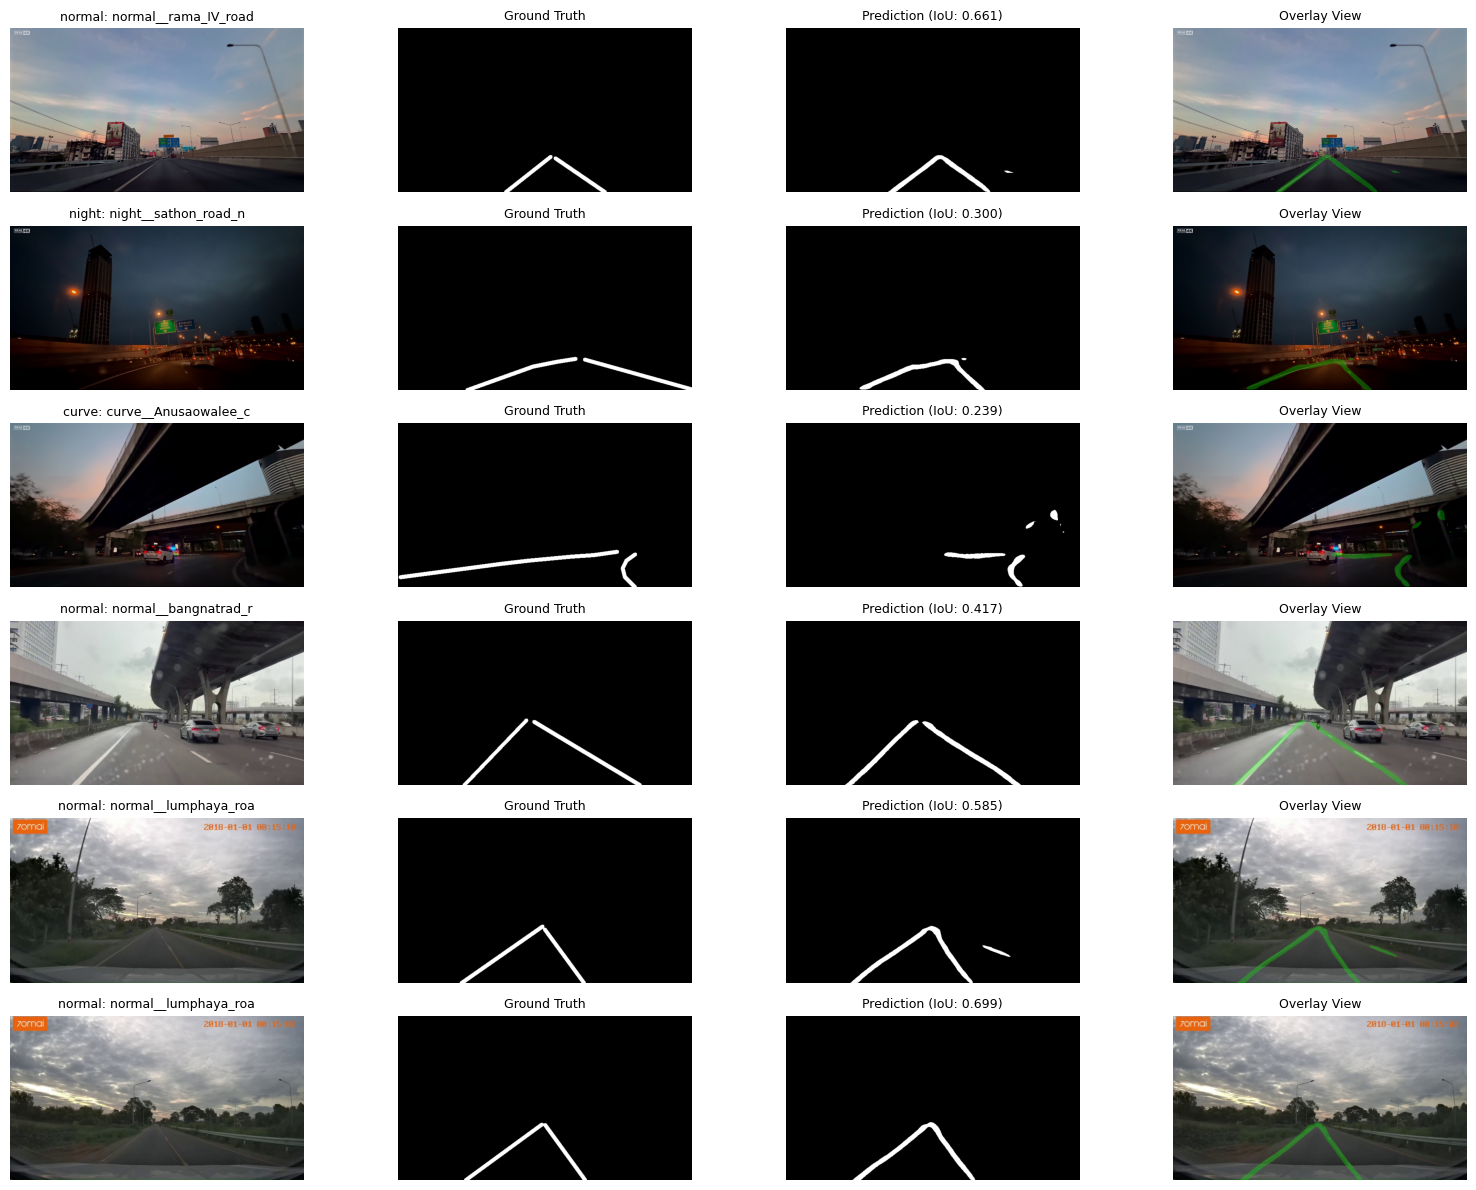

In [12]:
import random

# สุ่มตัวอย่างภาพจาก test set
random.seed(42)
indices = random.sample(range(len(test_ds)), 6)

plt.figure(figsize=(16, 12))
eval_model.eval()

for row, idx in enumerate(indices):
    img_tensor, mask_tensor = test_ds[idx]
    fname = test_ds.samples[idx]
    cat = test_ds.categories[idx]

    with torch.inference_mode():
        inp = img_tensor.unsqueeze(0).to(device)
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            out = eval_model(inp)
        pred = (torch.sigmoid(out.float())[0, 0] > 0.5).cpu().numpy().astype(np.uint8)

    gt = mask_tensor[0].numpy().astype(np.uint8)
    iou = calculate_iou(torch.from_numpy(pred), torch.from_numpy(gt))

    # แปลงภาพกลับ RGB
    raw_img = (img_tensor.numpy().transpose(1, 2, 0) * test_ds.std + test_ds.mean) * 255.0
    raw_img = np.clip(raw_img, 0, 255).astype(np.uint8)

    # ทำภาพ Overlay
    overlay = raw_img.copy()
    overlay[pred == 1] = [0, 255, 0]  # เขียว = เส้นเลนที่โมเดลทำนาย
    blended = cv2.addWeighted(raw_img, 0.7, overlay, 0.3, 0)

    # วาด 4 ช่องต่อภาพ
    plt.subplot(6, 4, row*4 + 1)
    plt.imshow(raw_img)
    plt.title(f"{cat}: {fname[:20]}", fontsize=9)
    plt.axis("off")

    plt.subplot(6, 4, row*4 + 2)
    plt.imshow(gt, cmap="gray")
    plt.title("Ground Truth", fontsize=9)
    plt.axis("off")

    plt.subplot(6, 4, row*4 + 3)
    plt.imshow(pred, cmap="gray")
    plt.title(f"Prediction (IoU: {iou:.3f})", fontsize=9)
    plt.axis("off")

    plt.subplot(6, 4, row*4 + 4)
    plt.imshow(blended)
    plt.title("Overlay View", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()